# 05: decision tree

**The algorithm.** Repeatedly split the data on the feature and threshold that best separate the classes, until a depth limit.

**Where the time goes.** For every node, try every feature and every cut point, and count classes on each side. There's no matrix math at all: it's branchy, integer counting work. GPUs and Accelerate can't help, which is exactly the case where **compiled code is supposed to win** (see the lesson on bottlenecks).

**Two different algorithms, on purpose.**
- scikit-learn's `DecisionTreeClassifier` sorts each feature's values and tries every exact cut.
- autoalgo's engines use the **histogram** method from LightGBM: bucket each feature into at most 256 bins once, then only count bins. It's much less work per node, and accuracy is usually about the same.

So this race mixes "better algorithm" with "faster engine". The `autoalgo-numpy` vs `autoalgo-rust` comparison isolates the engine: they run the identical algorithm and grow node-for-node identical trees (checked below).

In [1]:
import sys
sys.path.insert(0, ".")  # so bench_utils (next to this notebook) imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import autoalgo as aa
from bench_utils import (machine_info, timeit, load_covtype, add_speedup,
                         save_results, line_chart, fmt_ms)

pd.set_option("display.float_format", "{:,.4f}".format)
%matplotlib inline
pd.Series(machine_info())

chip                                  Apple M4
cores             4 performance + 6 efficiency
ram_gb                                      24
os         macOS-26.6.1-arm64-arm-64bit-Mach-O
python                                  3.13.5
numpy                       2.5.4 (accelerate)
sklearn                                  1.9.1
mlx                                     0.32.4
dtype: object

In [2]:
QUICK = False
from sklearn.tree import DecisionTreeClassifier as SkTree

X, y = load_covtype()
if QUICK:
    X, y = X[:60_000], y[:60_000]
X_test, y_test = X[:50_000], y[:50_000]
X_train, y_train = X[50_000:], y[50_000:]

def race(depth, n):
    Xt, yt = X_train[:n], y_train[:n]
    models = {
        "sklearn": lambda: SkTree(max_depth=depth, random_state=0),
        "autoalgo-numpy": lambda: aa.DecisionTreeClassifier(depth, backend="numpy"),
        "autoalgo-rust": lambda: aa.DecisionTreeClassifier(depth, backend="rust"),
    }
    out, trees = [], {}
    for name, make in models.items():
        fitted = {}
        def run():
            fitted["m"] = make().fit(Xt, yt)
        fit_s = timeit(run, repeats=1, warmup=False)
        m = fitted["m"]
        trees[name] = m
        out.append({"depth": depth, "train rows": n, "engine": name, "fit s": fit_s,
                    "predict s": timeit(lambda: m.predict(X_test), repeats=3),
                    "test accuracy": m.score(X_test, y_test),
                    "nodes": m.tree_.node_count if name == "sklearn" else m.node_count})
    a, b = trees["autoalgo-numpy"].tree_, trees["autoalgo-rust"].tree_
    identical = all(np.array_equal(a[key], b[key]) for key in a)
    return out, identical
print(f"train {len(X_train):,} rows, test {len(X_test):,} rows")

train 531,012 rows, test 50,000 rows


## Race 1: deeper trees (all training rows)

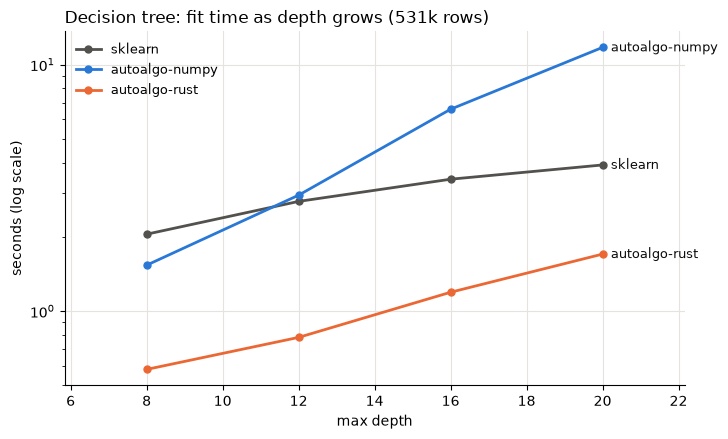

,depth,numpy and rust trees identical
0,8,True
1,12,True
2,16,True
3,20,True


,depth,train rows,engine,fit s,predict s,test accuracy,nodes,vs sklearn
0,8,531012,sklearn,2.0499,0.0025,0.7447,487,1.0000
1,8,531012,autoalgo-numpy,1.5348,0.0031,0.7472,445,1.3356
2,8,531012,autoalgo-rust,0.5796,0.0004,0.7472,445,3.5370
3,12,531012,sklearn,2.7849,0.0032,0.8102,3761,1.0000
4,12,531012,autoalgo-numpy,2.9518,0.0049,0.8130,3797,0.9434
5,12,531012,autoalgo-rust,0.7816,0.0004,0.8130,3797,3.5630
6,16,531012,sklearn,3.4263,0.0044,0.8677,13469,1.0000
7,16,531012,autoalgo-numpy,6.5881,0.0061,0.8717,14719,0.5201
8,16,531012,autoalgo-rust,1.1916,0.0006,0.8717,14719,2.8753
9,20,531012,sklearn,3.9148,0.0054,0.9084,27807,1.0000


In [3]:
rows, same = [], []
for depth in ([6, 10] if QUICK else [8, 12, 16, 20]):
    r, identical = race(depth, len(X_train))
    rows += r
    same.append({"depth": depth, "numpy and rust trees identical": identical})
by_depth = add_speedup(pd.DataFrame(rows), "fit s", ["depth"])
line_chart(by_depth, "depth", "fit s", "Decision tree: fit time as depth grows (531k rows)",
           "max depth", "seconds (log scale)", logx=False)
plt.show()
display(pd.DataFrame(same))
by_depth

## Race 2: more training rows (depth 16)

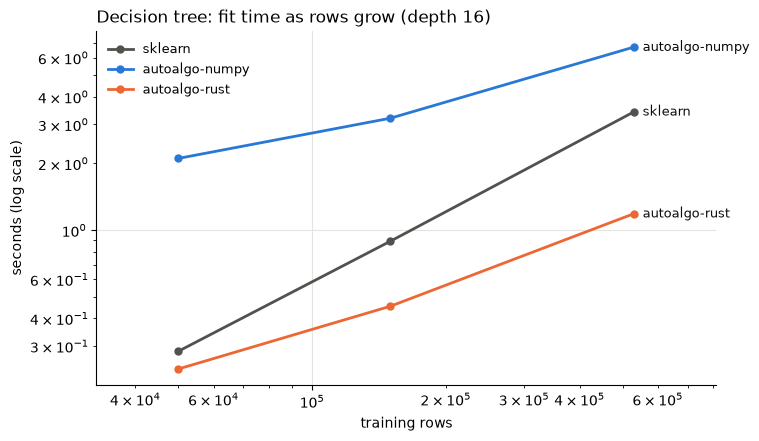

engine,autoalgo-numpy,autoalgo-rust,sklearn
train rows,,,
50000,0.1300,1.2000,1.0000
150000,0.2800,1.9600,1.0000
531012,0.5100,2.8800,1.0000


In [4]:
rows = []
for n in ([20_000, 50_000] if QUICK else [50_000, 150_000, len(X_train)]):
    rows += race(16 if not QUICK else 10, n)[0]
by_rows = add_speedup(pd.DataFrame(rows), "fit s", ["train rows"])
line_chart(by_rows, "train rows", "fit s", "Decision tree: fit time as rows grow (depth 16)",
           "training rows", "seconds (log scale)")
plt.show()
by_rows.pivot(index="train rows", columns="engine", values="vs sklearn").round(2)

## Prediction speed

Walking a row down a tree is pointer-chasing: each step jumps to an unpredictable place in memory.

In [5]:
pred = add_speedup(by_depth.rename(columns={"vs sklearn": "fit vs sklearn"}), "predict s", ["depth"])
pred.pivot(index="depth", columns="engine", values="vs sklearn").round(2)

engine,autoalgo-numpy,autoalgo-rust,sklearn
depth,,,
8,0.8000,6.3000,1.0000
12,0.6400,8.4200,1.0000
16,0.7200,7.3000,1.0000
20,0.7200,6.0400,1.0000


In [6]:
save_results("tree", by_depth, notes={"by_rows": by_rows.to_dict(orient="records")})
summary = by_depth[by_depth["depth"] == by_depth["depth"].max()].set_index("engine")
summary[["fit s", "vs sklearn", "test accuracy", "nodes"]]

,fit s,vs sklearn,test accuracy,nodes
engine,,,,
sklearn,3.9148,1.0000,0.9084,27807
autoalgo-numpy,11.7407,0.3334,0.9111,30719
autoalgo-rust,1.7021,2.2999,0.9111,30719
